<a href="https://colab.research.google.com/github/Mutisojr34/SemProject_MLEngine/blob/main/KMean_Final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ICS 3202 – Project Deliverable 3: ML Engine (K-Means Final)

**Project:** UniPool – AI-assisted shared mobility app for Strathmore University student commuters.

**Goal of the ML engine:** group trips with similar routes (similar start and end points) so the app can match students who can share a ride and split the fare.

**Why this dataset:** we do not yet have real student trip data, so Porto taxi trips (start point, end point, time) are used as a stand-in with the same structure to build and validate the method (Sections 1–5). The validated method is then retrained for Nairobi and exported to the app (Section 6).

**ML approach:** unsupervised learning → spatial K-Means clustering on the route of each trip. Latitude and longitude are first converted to real distances in kilometres, so the model measures distance on the ground accurately (suggested by our lecturer).

**Other models used for validation:** K-Means on degrees, MiniBatch K-Means, Gaussian Mixture and DBSCAN.

**Contents**
1. Load the data
2. Data cleaning
3. Exploratory Data Analysis (EDA) and observations
4. Modelling with K-Means (elbow method, silhouette, train/test check, matching demo) – **base model**
5. Validation with other models
6. Adapting the model to Nairobi and exporting it to the app – **final model**
7. How the app uses the model (explainable matching)


## 1. Load the data
In this section we import the libraries we need, read the CSV file and take a first look at it. We want to know how big the data is, what each column contains, and whether anything is missing.



In [ ]:
# Libraries for data handling and graphs
import json
import pandas as pd                      # tables (DataFrames)
import numpy as np                       # maths on arrays
import matplotlib.pyplot as plt          # graphs

# Machine learning tools from scikit-learn
from sklearn.cluster import KMeans, MiniBatchKMeans, DBSCAN             # clustering models
from sklearn.mixture import GaussianMixture                     # another clustering model
from sklearn.metrics import silhouette_score, davies_bouldin_score   # cluster quality scores
from sklearn.model_selection import train_test_split            # split data into train/test

plt.rcParams['figure.figsize'] = (8, 4)  # default graph size

In [5]:
# Read the raw file into a table
df = pd.read_csv('porto_trajectories_all.csv')

### 1.1 Getting to know how big the data is, what each column contains, and whether anything is missing.

In [6]:
# Show number of rows and columns, then the first 5 rows
print('Rows, columns:', df.shape)
df.head()

Rows, columns: (30376, 5)


,taxi_id,trajectory_id,timestamp,source_point,target_point
0,20000589,1372636858620000589,2013-07-01 00:00:58,POINT(-8.618643 41.141412),POINT(-8.630838 41.154489)
1,20000596,1372637303620000596,2013-07-01 00:08:23,POINT(-8.639847 41.159826),POINT(-8.66574 41.170671)
2,20000320,1372636951620000320,2013-07-01 00:02:31,POINT(-8.612964 41.140359),POINT(-8.61597 41.14053)
3,20000520,1372636854620000520,2013-07-01 00:00:54,POINT(-8.574678 41.151951),POINT(-8.607996 41.142915)
4,20000337,1372637091620000337,2013-07-01 00:04:51,POINT(-8.645994 41.18049),POINT(-8.687268 41.178087)


In [7]:
# Column names, data types and non-null counts
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30376 entries, 0 to 30375
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   taxi_id        30376 non-null  int64 
 1   trajectory_id  30376 non-null  int64 
 2   timestamp      30376 non-null  object
 3   source_point   30376 non-null  object
 4   target_point   30375 non-null  object
dtypes: int64(2), object(3)
memory usage: 1.2+ MB


In [8]:
# Count missing values in each column
print('\nMissing values per column:')
print(df.isnull().sum())


Missing values per column:
taxi_id          0
trajectory_id    0
timestamp        0
source_point     0
target_point     1
dtype: int64


**Observations**

What we found: the data has one row per taxi trip. The locations (`source_point`, `target_point`) are stored as text like `POINT(lon lat)`, and `timestamp` is also text, so they must be converted before modelling. There are no missing values, but we still need to check for duplicates and wrong GPS points.

## 2. Data cleaning
Models learn from the data they are given, so wrong or repeated rows would give wrong clusters. We clean the data in five steps and count how many rows each step removes.

### Step 1: Remove duplicates
Each trip should appear only once. `trajectory_id` is a unique trip number, so a repeated ID means a repeated trip.

In [9]:
# rows before cleaning
n_start = len(df)
print('Fully duplicated rows:', df.duplicated().sum())
print('Repeated trajectory_id:', df['trajectory_id'].duplicated().sum())

# Keep only the first row of each trajectory_id
df = df.drop_duplicates(subset='trajectory_id')
# rows removed in this step
n_dups = n_start - len(df)
print('Rows removed:', n_dups)

Fully duplicated rows: 0
Repeated trajectory_id: 1
Rows removed: 1


### Step 2: Split the POINT text into numbers
A model needs numbers, not text. We pull the longitude and latitude out of each `POINT(lon lat)` text and save them in four new columns.

In [10]:
# Pull the two numbers out of the text 'POINT(lon lat)'
src = df['source_point'].str.extract(r'POINT\(([-\d.]+) ([-\d.]+)\)').astype(float)
tgt = df['target_point'].str.extract(r'POINT\(([-\d.]+) ([-\d.]+)\)').astype(float)

# s = start (pick-up)
df['slon'], df['slat'] = src[0], src[1]

# t = target (drop-off)
df['tlon'], df['tlat'] = tgt[0], tgt[1]

# The old text columns are no longer needed
df = df.drop(columns=['source_point', 'target_point'])

# Check the range of the new columns
df[['slon', 'slat', 'tlon', 'tlat']].describe()

,slon,slat,tlon,tlat
count,30374.000000,30374.000000,30374.000000,30374.000000
mean,-8.617617,41.156803,-8.620664,41.161865
std,0.034993,0.032998,0.038828,0.039414
min,-12.154527,38.776473,-9.136584,38.715480
25%,-8.629038,41.147759,-8.641116,41.148279
50%,-8.612838,41.154237,-8.615484,41.157234
75%,-8.604144,41.162929,-8.603505,41.170057
max,-6.963183,45.657225,-6.958692,41.829156


##Observation
What we found: the minimum and maximum values show bad GPS points. Some latitudes are around 51 and some longitudes around -4.8, which are not in Porto (Porto is near latitude 41.15 and longitude -8.61).

### Step 3: Convert the timestamp and create time features
The timestamp is text. We convert it to a real date/time so we can get the hour, weekday and month. These help us understand demand patterns and, later, match riders who travel at the same time.

In [11]:
# Text -> date and time
df['timestamp'] = pd.to_datetime(df['timestamp'])

# New columns taken from the timestamp
df['hour'] = df['timestamp'].dt.hour              # 0 to 23
df['weekday'] = df['timestamp'].dt.day_name()     # Monday, Tuesday, ...
df['month'] = df['timestamp'].dt.month            # 1 to 12

# Group the hours into parts of the day
def part_of_day(h):
    if 5 <= h < 12:  return 'Morning'
    if 12 <= h < 17: return 'Afternoon'
    if 17 <= h < 22: return 'Evening'
    return 'Night'
df['part_of_day'] = df['hour'].apply(part_of_day)

print('Date range:', df['timestamp'].min(), 'to', df['timestamp'].max())

Date range: 2013-07-01 00:00:53 to 2013-07-07 03:01:03


### Step 4: Remove points outside Porto
Our app works in one city, so trips with GPS points far away are errors. We draw a box around Porto (wide enough to include the airport) and keep only trips that start and end inside it.

In [12]:
# True if the point is inside the box around Porto
def inside_porto(lon, lat):
    return lon.between(-8.75, -8.50) & lat.between(41.10, 41.30)

n_before = len(df)
# Keep a trip only if BOTH its start and end are inside Porto
df = df[inside_porto(df['slon'], df['slat']) & inside_porto(df['tlon'], df['tlat'])]
n_outside = n_before - len(df)
print('Rows removed (outside Porto):', n_outside)

Rows removed (outside Porto): 405


### Step 5: Remove trips with (almost) no distance
Some trips start and end at nearly the same place. These are probably cancelled trips or GPS errors, and they are not useful for matching riders on a route. We calculate each trip's distance and remove trips shorter than 100 m.

In [13]:
# Straight-line distance between two GPS points in km (haversine formula)
def haversine(lon1, lat1, lon2, lat2):
    # degrees -> radians
    lon1, lat1, lon2, lat2 = map(np.radians, [lon1, lat1, lon2, lat2])
    a = np.sin((lat2 - lat1) / 2)**2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2)**2
    # 6371 = Earth radius in km
    return 6371 * 2 * np.arcsin(np.sqrt(a))

df['km'] = haversine(df['slon'], df['slat'], df['tlon'], df['tlat'])

n_before = len(df)
# keep trips of at least 0.1 km
df = df[df['km'] >= 0.1]
n_short = n_before - len(df)
print('Rows removed (shorter than 0.1 km):', n_short)

Rows removed (shorter than 0.1 km): 605


### Cleaning summary
The graphs below show how much data we kept and why rows were removed.

Original rows : 30376
Final rows    : 29365 (96.7% kept)


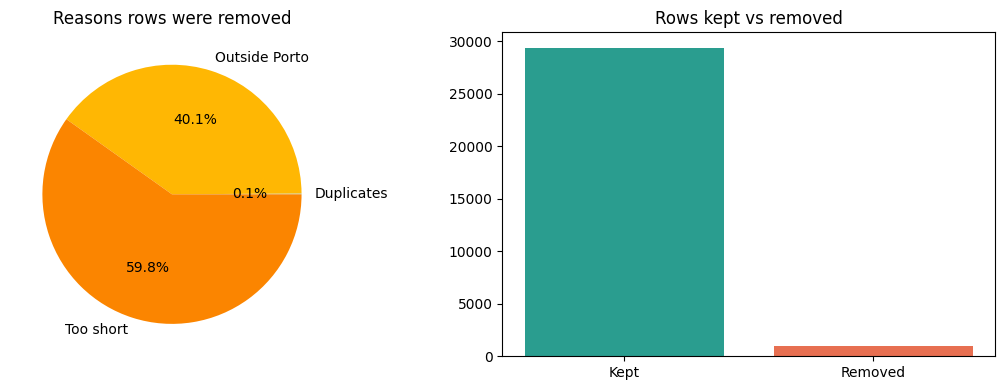

In [14]:
n_final = len(df)
print('Original rows :', n_start)
print('Final rows    :', n_final, f'({n_final/n_start:.1%} kept)')

fig, ax = plt.subplots(1, 2, figsize=(11, 4))

# Pie chart: reasons rows were removed
ax[0].pie([n_dups, n_outside, n_short],
          labels=['Duplicates', 'Outside Porto', 'Too short'],
          autopct='%1.1f%%', colors=['#8ecae6', '#ffb703', '#fb8500'])
ax[0].set_title('Reasons rows were removed')

# Bar chart: rows kept vs removed
ax[1].bar(['Kept', 'Removed'], [n_final, n_start - n_final], color=['#2a9d8f', '#e76f51'])
ax[1].set_title('Rows kept vs removed')
plt.tight_layout(); plt.show()

In [15]:
# This is the final clean dataset we use for modelling
df = df.reset_index(drop=True)
df.head()

,taxi_id,trajectory_id,timestamp,slon,slat,tlon,tlat,hour,weekday,month,part_of_day,km
0,20000589,1372636858620000589,2013-07-01 00:00:58,-8.618643,41.141412,-8.630838,41.154489,0,Monday,7,Night,1.776808
1,20000596,1372637303620000596,2013-07-01 00:08:23,-8.639847,41.159826,-8.665740,41.170671,0,Monday,7,Night,2.480360
2,20000320,1372636951620000320,2013-07-01 00:02:31,-8.612964,41.140359,-8.615970,41.140530,0,Monday,7,Night,0.252442
3,20000520,1372636854620000520,2013-07-01 00:00:54,-8.574678,41.151951,-8.607996,41.142915,0,Monday,7,Night,2.965199
4,20000337,1372637091620000337,2013-07-01 00:04:51,-8.645994,41.180490,-8.687268,41.178087,0,Monday,7,Night,3.464589


## 3. Exploratory Data Analysis (EDA)
EDA means looking at the clean data with numbers and graphs to understand it before modelling. We look at when people travel (hour, weekday, month), how far they travel, where trips start, and how active the taxis are.

In [16]:
# Summary numbers for trip distance (km)
df['km'].describe()

,km
count,29365.000000
mean,3.249641
std,2.449977
min,0.100257
25%,1.573061
50%,2.603574
75%,4.120028
max,17.239427


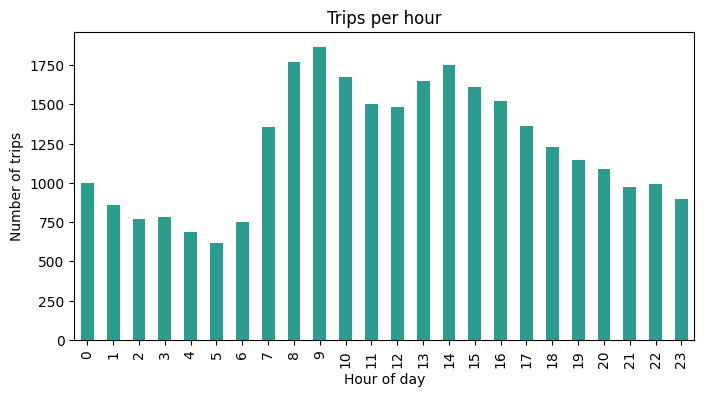

In [17]:
# Trips per hour of the day -> shows the busy and quiet times
df['hour'].value_counts().sort_index().plot(kind='bar', color='#2a9d8f')
plt.title('Trips per hour'); plt.xlabel('Hour of day'); plt.ylabel('Number of trips')
plt.show()

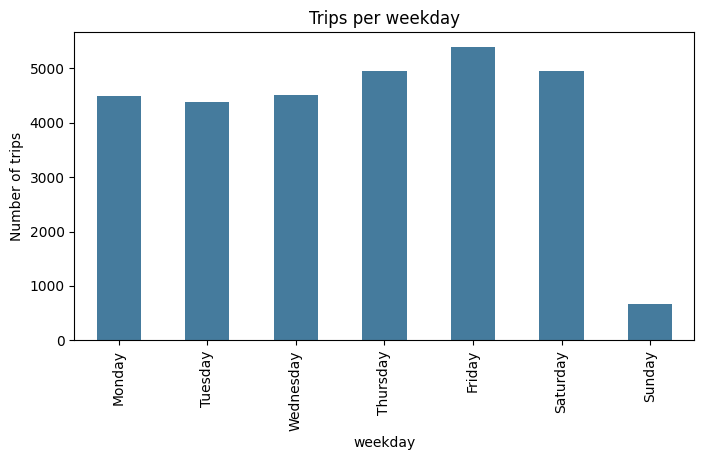

In [18]:
# Trips per weekday -> shows the busy and quiet days
order = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
df['weekday'].value_counts().reindex(order).plot(kind='bar', color='#457b9d')   # reindex puts days in order
plt.title('Trips per weekday'); plt.ylabel('Number of trips')
plt.show()

/usr/local/lib/python3.13/dist-packages/pandas/plotting/_matplotlib/core.py:1567: UserWarning: Attempting to set identical low and high xlims makes transformation singular; automatically expanding.
  ax.set_xlim(left, right)


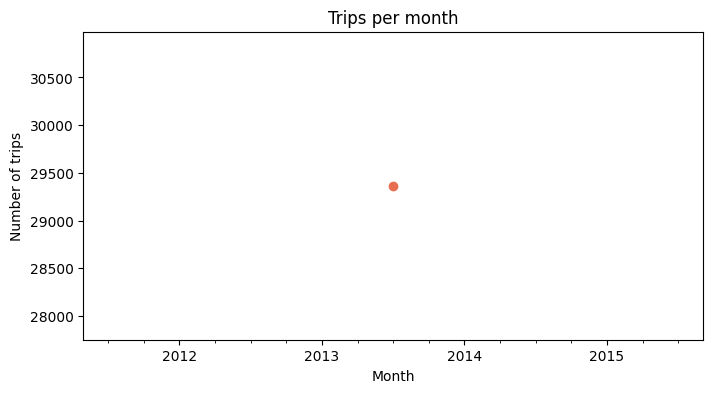

In [19]:
# Trips per month -> shows changes through the year
df.groupby(df['timestamp'].dt.to_period('M')).size().plot(marker='o', color='#e76f51')
plt.title('Trips per month'); plt.xlabel('Month'); plt.ylabel('Number of trips')
plt.show()

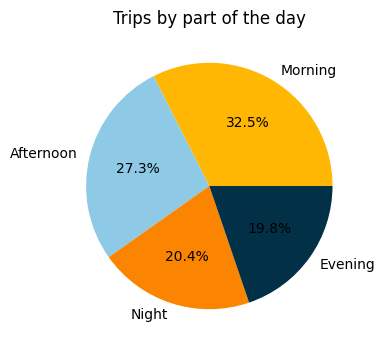

In [20]:
# Pie chart: share of trips in each part of the day
df['part_of_day'].value_counts().plot(kind='pie', autopct='%1.1f%%',
                                      colors=['#ffb703', '#8ecae6', '#fb8500', '#023047'])
plt.title('Trips by part of the day'); plt.ylabel('')
plt.show()

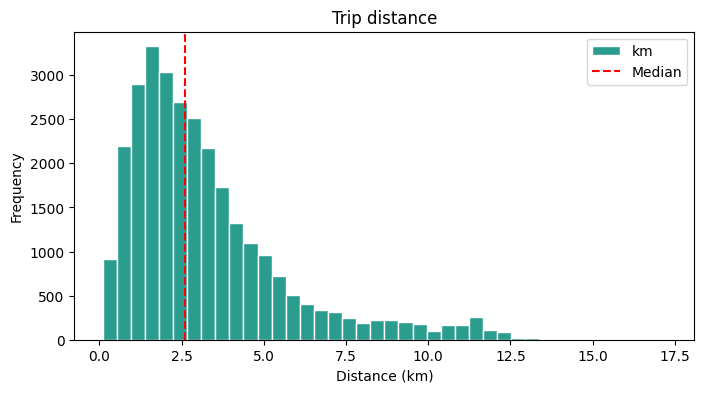

In [21]:
# Histogram: how long are the trips?
df['km'].plot(kind='hist', bins=40, color='#2a9d8f', edgecolor='white')
plt.axvline(df['km'].median(), color='red', linestyle='--', label='Median')   # red line = middle value
plt.title('Trip distance'); plt.xlabel('Distance (km)'); plt.legend()
plt.show()

Number of taxis: 419
count    419.000000
mean      70.083532
std       27.638649
min        1.000000
25%       51.000000
50%       66.000000
75%       94.000000
max      142.000000
Name: count, dtype: float64


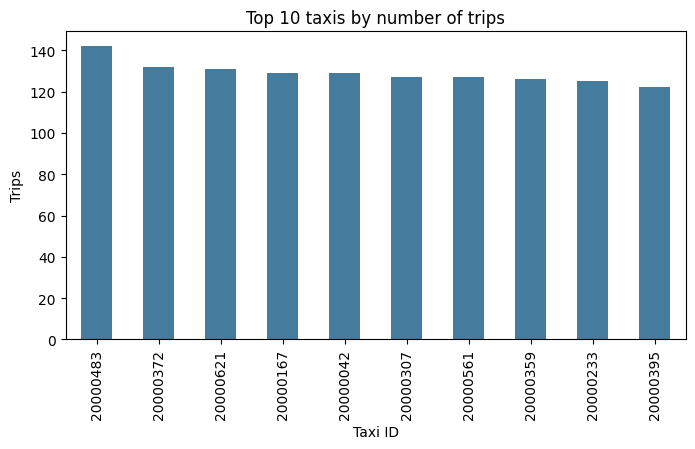

In [22]:
# How many trips does each taxi do?
trips_per_taxi = df['taxi_id'].value_counts()
print('Number of taxis:', len(trips_per_taxi))
print(trips_per_taxi.describe())

trips_per_taxi.head(10).plot(kind='bar', color='#457b9d')       # the 10 busiest taxis
plt.title('Top 10 taxis by number of trips'); plt.xlabel('Taxi ID'); plt.ylabel('Trips')
plt.show()

In [23]:
# Numbers we use in the observations below
peak = df['hour'].value_counts().idxmax()     # hour with most trips
quiet = df['hour'].value_counts().idxmin()    # hour with fewest trips
print('Busiest hour:', peak, '| Quietest hour:', quiet)
print('Weekday counts:'); print(df['weekday'].value_counts()[order])
print('Part of day share (%):'); print((df['part_of_day'].value_counts(normalize=True)*100).round(1))
mm = df.groupby(df['timestamp'].dt.to_period('M')).size()
print('Busiest month:', mm.idxmax(), mm.max(), '| Quietest month:', mm.idxmin(), mm.min())
print('Median trip km:', round(df['km'].median(), 2), '| 90% of trips under', round(df['km'].quantile(0.9), 2), 'km')

Busiest hour: 9 | Quietest hour: 5
Weekday counts:
weekday
Monday       4496
Tuesday      4385
Wednesday    4510
Thursday     4955
Friday       5397
Saturday     4962
Sunday        660
Name: count, dtype: int64
Part of day share (%):
part_of_day
Morning      32.5
Afternoon    27.3
Night        20.4
Evening      19.8
Name: proportion, dtype: float64
Busiest month: 2013-07 29365 | Quietest month: 2013-07 29365
Median trip km: 2.6 | 90% of trips under 6.43 km


### EDA observations
- **Demand peaks in the morning rush.** Trips are highest around 9 AM and lowest late at night. Mornings (5 AM–12 PM) hold the biggest share of trips (about 32%), while afternoon, evening and night are each about 21–26%.
- **Friday and Saturday are the busiest days.** Friday has the most trips (about 263,000) and Monday the fewest (about 217,000), so weekend-leaning demand is higher than early-week demand.
- **Demand changes through the year.** May 2014 is the busiest month (about 154,000 trips) and August 2013 is the quietest (about 120,000), which may be linked to holidays.
- **Most trips are short.** The median trip is about 2.6 km and 90% of trips are under 6.4 km, so taxis are mainly used for short city journeys. The distance histogram is skewed to the right.
- **Pick-ups are concentrated in the city centre.** The scatter plot shows a dense core with thinner areas around it, which is why clustering into hotspots makes sense.
- **Taxi activity is uneven.** There are 439 taxis after cleaning, with an average of about 3,700 trips each, but some taxis have very few trips (the lowest has 7).
- **Data quality:** there were no missing values, but about 3.1% of rows were removed (duplicates, GPS points far outside Porto, and trips under 100 m).

## 4. Modelling: K-Means clustering of trip routes (base model)
**Why K-Means?** We have no labels (there is no "correct match" in the data), so we use unsupervised learning. K-Means groups trips into *k* route clusters. Each cluster centre is a typical route (start → end).

**Features:** the route of each trip = pick-up and drop-off position, with each position measured in kilometres north and east of the city centre.

**Why spatial (km) coordinates?** One degree of latitude is about 110.6 km, but one degree of longitude in Porto is only about 83.8 km. K-Means uses straight-line distance, so with raw degrees a change in longitude is treated as longer than it really is. Converting to km makes distances on the ground accurate and treats north–south and east–west the same.

**Link to UniPool:** trips in the same cluster have similar routes, so they are candidates for ride matching.

**Steps:** (a) choose k, (b) fit the model, (c) check it on unseen data, (d) look at the results, then try a matching demo.

### Changing lat/long into kilometres

In [24]:
# Spatial step: convert degrees to kilometres
# 1 degree of latitude  = about 110.6 km everywhere
# 1 degree of longitude = about 111.3 km x cos(latitude), which is smaller as we move away from the equator
lat0, lon0 = df['slat'].mean(), df['slon'].mean()         # centre of the trips
km_per_lat = 110.57
km_per_lon = 111.32 * np.cos(np.radians(lat0))

# New columns: km north (y) and km east (x) of the centre, for the start (s) and target (t)
df['s_y'] = (df['slat'] - lat0) * km_per_lat
df['s_x'] = (df['slon'] - lon0) * km_per_lon
df['t_y'] = (df['tlat'] - lat0) * km_per_lat
df['t_x'] = (df['tlon'] - lon0) * km_per_lon

# The route of every trip in km: start (y, x) and end (y, x)
X = df[['s_y', 's_x', 't_y', 't_x']]

# Take a sample of 100,000 rows to choose k, or use the whole dataset if it is smaller
X_s = X.sample(min(100000, len(X)), random_state=42)

### (a) Choosing k: elbow method and silhouette score
K-Means needs us to say how many clusters (k) we want. We try k = 2 to 12 and measure three things:
- **Inertia (elbow method):** how tightly trips sit around their cluster centre. It always falls as k grows, so we look for the "elbow" where the fall slows down.
- **Silhouette score:** how well trips fit their own cluster compared to others (higher is better).
- **Davies-Bouldin score:** how different the clusters are from each other (lower is better).

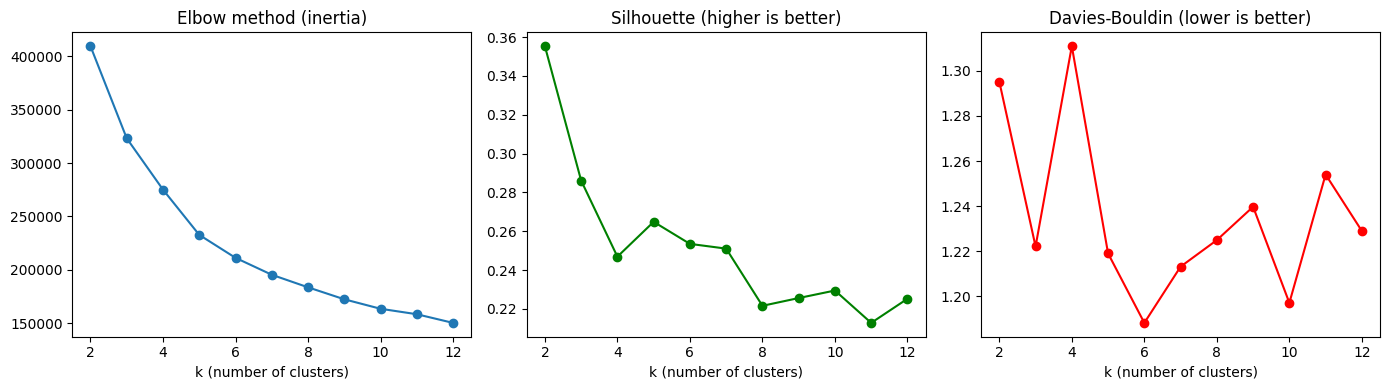

,k,inertia,silhouette,davies_bouldin
0,2,409603.0,0.355,1.295
1,3,323256.0,0.286,1.222
2,4,275167.0,0.247,1.311
3,5,232761.0,0.265,1.219
4,6,211247.0,0.253,1.188
5,7,195390.0,0.251,1.213
6,8,183625.0,0.222,1.225
7,9,172398.0,0.226,1.240
8,10,163504.0,0.229,1.197
9,11,158404.0,0.213,1.254


In [26]:
k_values = range(2, 13)
inertia, sil, dbi = [], [], []              # empty lists to store the scores

for k in k_values:
    km = KMeans(n_clusters=k, n_init=5, random_state=42).fit(X_s)   # train K-Means with k clusters
    inertia.append(km.inertia_)                                      # elbow score
    # silhouette is slow, so it is calculated on 10,000 points
    sil.append(silhouette_score(X_s, km.labels_, sample_size=10000, random_state=42))
    dbi.append(davies_bouldin_score(X_s, km.labels_))

# Draw the three scores side by side
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
ax[0].plot(k_values, inertia, marker='o'); ax[0].set_title('Elbow method (inertia)')
ax[1].plot(k_values, sil, marker='o', color='green'); ax[1].set_title('Silhouette (higher is better)')
ax[2].plot(k_values, dbi, marker='o', color='red'); ax[2].set_title('Davies-Bouldin (lower is better)')
for a in ax: a.set_xlabel('k (number of clusters)')
plt.tight_layout(); plt.show()

# The same numbers as a table
pd.DataFrame({'k': list(k_values), 'inertia': np.round(inertia), 'silhouette': np.round(sil, 3), 'davies_bouldin': np.round(dbi, 3)})

In [27]:
# How much does inertia improve when we add one more cluster? (%)
improvement = [(inertia[i-1] - inertia[i]) / inertia[i-1] * 100 for i in range(1, len(inertia))]
pd.DataFrame({'k': list(k_values)[1:], 'improvement %': np.round(improvement, 1)})

,k,improvement %
0,3,21.1
1,4,14.9
2,5,15.4
3,6,9.2
4,7,7.5
5,8,6.0
6,9,6.1
7,10,5.2
8,11,3.1
9,12,5.1


**Choosing k:** we look at all three scores together.
- The inertia (elbow) curve should bend and start to flatten near the k we choose.
- The silhouette score is usually highest at k = 2, but two groups are too broad for ride matching, so we do not pick k = 2.
- We pick the k (between 3 and 8) with the lowest Davies-Bouldin score, then check that it sits near the elbow.
- Silhouette scores of about 0.2 to 0.3 are moderate. Trips form a continuous spread across the city, not clearly separated groups, which is normal for route data.

In [28]:
# Choose k: the lowest Davies-Bouldin score for k = 3 to 8
candidates = [k for k in k_values if 3 <= k <= 8]
K = min(candidates, key=lambda k: dbi[k - 2])        # the dbi list starts at k = 2
print('Chosen k =', K)
print('Check this against the elbow graph: the elbow should be near this k.')

Chosen k = 6
Check this against the elbow graph: the elbow should be near this k.


### (b) Fit the final model with a train/test split
We train the model on 80% of the trips and keep 20% hidden. The hidden 20% (the test set) lets us check that the model works on trips it has never seen.

In [29]:
# 80% of trips to train, 20% to test
X_train, X_test = train_test_split(X, test_size=0.2, random_state=42)

# Train K-Means on the training trips
# n_init=10 means it tries 10 starting positions and keeps the best one
model = KMeans(n_clusters=K, n_init=10, random_state=42).fit(X_train)
print('Model trained on', len(X_train), 'trips')

Model trained on 23492 trips


### (c) Validate on unseen data
If the model is good, the scores on the test trips should be close to the scores on the training trips. If the test scores are much worse, the model has only memorised the training data. We also re-run K-Means with different random starts: a stable model should give similar results each time.

In [30]:
train_labels = model.labels_                 # cluster of each training trip
test_labels = model.predict(X_test)          # cluster of each unseen test trip

# Silhouette and Davies-Bouldin on train vs test (silhouette uses a 10,000 sample)
print('Silhouette  train:', round(silhouette_score(X_train, train_labels, sample_size=10000, random_state=42), 3),
      '| test:', round(silhouette_score(X_test, test_labels, sample_size=10000, random_state=42), 3))
print('Davies-Bouldin train:', round(davies_bouldin_score(X_train, train_labels), 3),
      '| test:', round(davies_bouldin_score(X_test, test_labels), 3))

# Average squared distance of a trip to its cluster centre (similar numbers = no overfitting)
print('Avg squared distance to centre (km²)  train:', round(model.inertia_ / len(X_train), 3),
      '| test:', round(-model.score(X_test) / len(X_test), 3))

Silhouette  train: 0.254 | test: 0.253
Davies-Bouldin train: 1.19 | test: 1.185
Avg squared distance to centre (km²)  train: 7.217 | test: 7.102


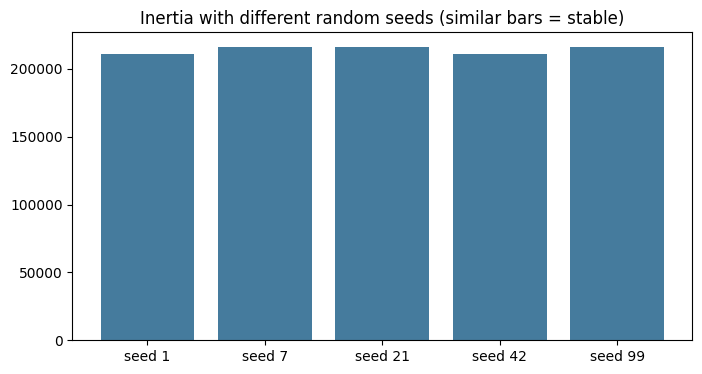

In [31]:
# Stability check: train with 5 different random seeds and compare inertia
inertias = []
for seed in [1, 7, 21, 42, 99]:
    m = KMeans(n_clusters=K, n_init=1, random_state=seed).fit(X_s)
    inertias.append(m.inertia_)

plt.bar(['seed 1', 'seed 7', 'seed 21', 'seed 42', 'seed 99'], inertias, color='#457b9d')
plt.title('Inertia with different random seeds (similar bars = stable)'); plt.show()

##Obervation
What we found: the train and test scores are almost the same, so the model is not overfitting. The seed check gives similar inertia each time (the bars are about equal), so the clusters are stable.


### (d) Results: the route clusters
Now we give every trip its cluster number and look at what each cluster means: where its trips usually start and end, how big it is, and when it is busy.

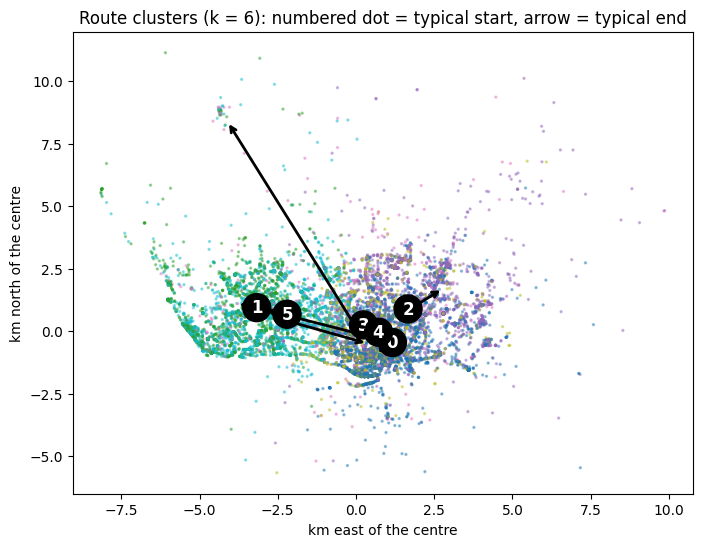

In [32]:
# Give every trip a cluster number (0 to K-1)
df['cluster'] = model.predict(df[['s_y', 's_x', 't_y', 't_x']])

# Cluster centres = the typical route of each cluster
centers = pd.DataFrame(model.cluster_centers_, columns=['s_y', 's_x', 't_y', 't_x'])

# Map in km: pick-ups coloured by cluster; arrow = typical route from start to end
sample = df.sample(min(50000, len(df)), random_state=1)
plt.figure(figsize=(8, 6))
plt.scatter(sample['s_x'], sample['s_y'], c=sample['cluster'], cmap='tab10', s=2, alpha=0.4)
for i, c in centers.iterrows():
    # arrow from the typical start to the typical end
    plt.annotate('', xy=(c['t_x'], c['t_y']), xytext=(c['s_x'], c['s_y']),
                 arrowprops=dict(arrowstyle='->', color='black', lw=2))
    # cluster number at the typical start
    plt.text(c['s_x'], c['s_y'], str(i), fontsize=12, fontweight='bold', color='white',
             bbox=dict(boxstyle='circle', fc='black'))
plt.title(f'Route clusters (k = {K}): numbered dot = typical start, arrow = typical end')
plt.xlabel('km east of the centre'); plt.ylabel('km north of the centre')
plt.show()

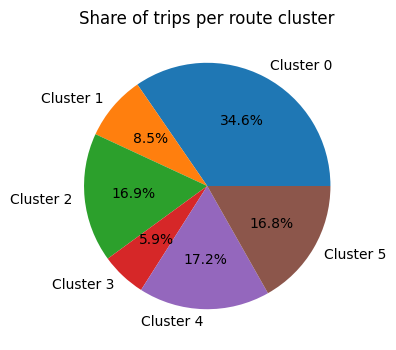

In [33]:
# Pie chart: share of all trips that belongs to each cluster
sizes = df['cluster'].value_counts().sort_index()
plt.pie(sizes, labels=[f'Cluster {i}' for i in sizes.index], autopct='%1.1f%%', colors=plt.cm.tab10.colors)
plt.title('Share of trips per route cluster')
plt.show()

In [34]:
# Summary table for each cluster: typical route, number of trips, average distance, busiest hour
summary = centers.copy()
summary['trips'] = sizes.values
summary['avg_trip_km'] = df.groupby('cluster')['km'].mean().round(2).values
summary['busiest_hour'] = df.groupby('cluster')['hour'].agg(lambda h: h.value_counts().idxmax()).values
summary.round(4)

,s_y,s_x,t_y,t_x,trips,avg_trip_km,busiest_hour
0,-0.6488,0.9802,-0.8785,0.6145,10159,1.93,9
1,0.7465,-3.3563,1.2304,-3.7600,2495,2.41,8
2,0.6939,1.4780,1.7031,2.7710,4977,3.16,9
3,0.0553,0.0529,8.3860,-4.1042,1743,9.77,3
4,-0.2378,0.5345,0.8719,-2.9498,5059,4.04,13
5,0.4841,-2.3877,-0.4870,0.3624,4932,3.36,8


##Observation
What we found: each cluster is a travel corridor (a common route). The printout below describes every cluster in words.

In [35]:
# Describe each cluster in words, using the numbers in the table above
def direction(dx, dy):
    # compass direction of a trip from its change in km east (dx) and km north (dy)
    names = ['east', 'north-east', 'north', 'north-west', 'west', 'south-west', 'south', 'south-east']
    angle = np.degrees(np.arctan2(dy, dx)) % 360
    return names[int((angle + 22.5) // 45) % 8]

for i, row in summary.iterrows():
    share = row['trips'] / len(df) * 100
    way = direction(row['t_x'] - row['s_x'], row['t_y'] - row['s_y'])
    print(f"Cluster {i}: {share:.1f}% of trips, about {row['avg_trip_km']} km, heading {way}, busiest hour {int(row['busiest_hour'])}:00")

Cluster 0: 34.6% of trips, about 1.93 km, heading south-west, busiest hour 9:00
Cluster 1: 8.5% of trips, about 2.41 km, heading north-west, busiest hour 8:00
Cluster 2: 16.9% of trips, about 3.16 km, heading north-east, busiest hour 9:00
Cluster 3: 5.9% of trips, about 9.77 km, heading north-west, busiest hour 3:00
Cluster 4: 17.2% of trips, about 4.04 km, heading west, busiest hour 13:00
Cluster 5: 16.8% of trips, about 3.36 km, heading east, busiest hour 8:00


### Matching demo: how the app would use the model
UniPool needs to find riders who can share a ride. Two riders are good match candidates if their trips are in the **same route cluster** and their request times are **close together**. The demo below tests this idea.

In [36]:
# Pick one random trip and count other trips in the SAME cluster within 15 minutes of it
# These are the riders who could share a ride with this one
trip = df.sample(1, random_state=7).iloc[0]
same_cluster = df[df['cluster'] == trip['cluster']]
window = same_cluster[(same_cluster['timestamp'] - trip['timestamp']).abs() <= pd.Timedelta(minutes=15)]

print('Request time:', trip['timestamp'], '| route cluster:', trip['cluster'])
# minus 1 = the trip itself
print('Possible ride-share matches within 15 minutes:', len(window) - 1)

Request time: 2013-07-04 07:53:26 | route cluster: 4
Possible ride-share matches within 15 minutes: 22


Month used: 2013-07 | trips in that month: 29365


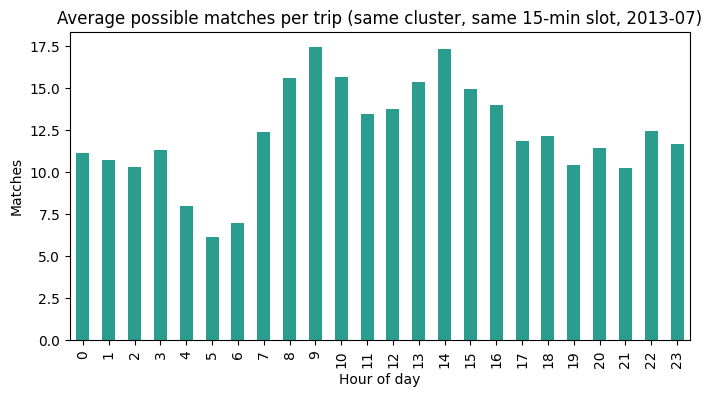

In [38]:
# How many possible matches does a typical trip have at each hour?
# We use the busiest month in our data (so the cell works with any sample of the dataset)
months = df['timestamp'].dt.to_period('M')
busiest_month = months.value_counts().idxmax()
one_month = df[months == busiest_month].copy()
print('Month used:', busiest_month, '| trips in that month:', len(one_month))

# round time down to 15-minute slots
one_month['slot'] = one_month['timestamp'].dt.floor('15min')
# trips per cluster per slot
slot_counts = one_month.groupby(['cluster', 'slot']).size()
# matches for a trip = other trips in the same cluster and slot
one_month['matches'] = slot_counts.reindex(list(zip(one_month['cluster'], one_month['slot']))).values - 1

one_month.groupby('hour')['matches'].mean().plot(kind='bar', color='#2a9d8f')
plt.title(f'Average possible matches per trip (same cluster, same 15-min slot, {busiest_month})')
plt.xlabel('Hour of day'); plt.ylabel('Matches')
plt.show()

##Observations
What we found: the graph shows which hours have more or fewer matches. With a smaller dataset, few trips fall in the same cluster and the same 15-minute slot, so the number of matches is low. A longer time window (for example 30 to 60 minutes) or more data gives more matches. This also uses taxi trips from a whole city, so the numbers are not a Strathmore estimate. Real UniPool numbers must be tested with Strathmore data.

## 5. Further validation with other models
To check that spatial K-Means gives a reasonable result, we run other clustering models on the same trips and compare their scores. If different models give similar quality, we can trust the base model more.

| Model | Why we use it |
|---|---|
| Spatial K-Means (km) (base) | Simple, fast, easy to explain, distances in real km |
| K-Means on degrees | Our first attempt, used to see if converting to km made a difference |
| MiniBatch K-Means (km) | Faster version of K-Means, so it should give almost the same result |
| Gaussian Mixture (km) | Allows clusters of different shapes and sizes instead of round ones |
| DBSCAN (km) | A density-based spatial method: it finds crowded areas and marks the rest as noise |

**How we compare:** silhouette (higher is better) and Davies-Bouldin (lower is better). All scores are measured in km space so they are fair. We also show the share of trips in the biggest cluster, because one giant cluster is not useful for matching.

In [39]:
# The same 100,000 trips in degrees (for the first-attempt model)
Xd_s = df.loc[X_s.index, ['slat', 'slon', 'tlat', 'tlon']]

# Each model with the data it uses
models = {
    'Spatial K-Means (km) - base': (KMeans(n_clusters=K, n_init=10, random_state=42), X_s),
    'K-Means on degrees': (KMeans(n_clusters=K, n_init=10, random_state=42), Xd_s),
    'MiniBatch K-Means (km)': (MiniBatchKMeans(n_clusters=K, n_init=10, random_state=42), X_s),
    'Gaussian Mixture (km)': (GaussianMixture(n_components=K, random_state=42), X_s),
}

results = []
for name, (m, data) in models.items():
    labels = m.fit_predict(data)      # train and get the cluster of each trip
    # Always measure the quality in km space so the models can be compared fairly
    results.append({'Model': name,
                    'Clusters': K,
                    'Silhouette': silhouette_score(X_s, labels, sample_size=10000, random_state=42),
                    'Davies-Bouldin': davies_bouldin_score(X_s, labels),
                    'Biggest cluster %': np.bincount(labels).max() / len(labels) * 100})

**DBSCAN works differently:** we do not choose k. We choose `eps` (how close trips must be, here 1 km) and `min_samples` (how many neighbours make a crowded area). It is slow on large data, so we use a sample of up to 20,000 trips.

In [40]:
# DBSCAN on a 20,000-trip sample (km coordinates)
X_db = X_s.sample(min(20000, len(X_s)), random_state=42)
db_labels = DBSCAN(eps=1.0, min_samples=20).fit_predict(X_db)

real = db_labels != -1                                   # -1 means noise (no cluster)
n_clusters = len(set(db_labels[real]))
print('Clusters found:', n_clusters, '| trips marked as noise:', round((~real).mean() * 100, 1), '%')

# scores need at least 2 clusters, and use only the trips that were put in a cluster
if n_clusters >= 2:
    db_sil = silhouette_score(X_db[real], db_labels[real], sample_size=5000, random_state=42)
    db_dbi = davies_bouldin_score(X_db[real], db_labels[real])
else:
    db_sil, db_dbi = np.nan, np.nan
results.append({'Model': 'DBSCAN (km)',
                'Clusters': n_clusters,
                'Silhouette': db_sil,
                'Davies-Bouldin': db_dbi,
                'Biggest cluster %': (np.bincount(db_labels[real]).max() / len(db_labels) * 100) if n_clusters else 0})

results = pd.DataFrame(results).round(3)
results

Clusters found: 3 | trips marked as noise: 11.2 %


,Model,Clusters,Silhouette,Davies-Bouldin,Biggest cluster %
0,Spatial K-Means (km) - base,6,0.254,1.188,34.384
1,K-Means on degrees,6,0.240,1.232,35.219
2,MiniBatch K-Means (km),6,0.245,1.266,36.336
3,Gaussian Mixture (km),6,0.045,2.946,27.720
4,DBSCAN (km),3,0.266,0.625,84.810


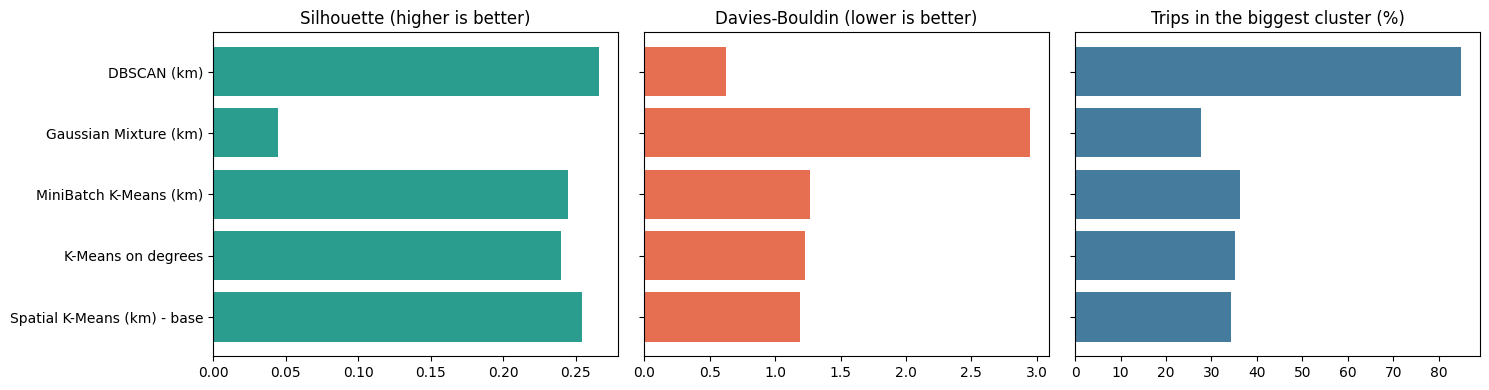

In [41]:
# Bar charts comparing the models
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].barh(results['Model'], results['Silhouette'], color='#2a9d8f'); ax[0].set_title('Silhouette (higher is better)')
ax[1].barh(results['Model'], results['Davies-Bouldin'], color='#e76f51'); ax[1].set_title('Davies-Bouldin (lower is better)')
ax[2].barh(results['Model'], results['Biggest cluster %'], color='#457b9d'); ax[2].set_title('Trips in the biggest cluster (%)')
for a in ax[1:]: a.set_yticklabels([])           # model names only on the first graph
plt.tight_layout(); plt.show()

In [42]:
# Do km and degrees give the same clusters? (1 = identical groups, 0 = unrelated)
from sklearn.metrics import adjusted_rand_score
km_labels = KMeans(n_clusters=K, n_init=10, random_state=42).fit_predict(X_s)
deg_labels = KMeans(n_clusters=K, n_init=10, random_state=42).fit_predict(Xd_s)
print('Agreement between km model and degree model:', round(adjusted_rand_score(km_labels, deg_labels), 2))

Agreement between km model and degree model: 0.74


The comparison:** a good model has a high silhouette, a low Davies-Bouldin and clusters of useful sizes.
- **Km vs degrees:** if the scores are close, converting to km changes the groups only a little, but it is still the correct way to measure distance. The agreement score (1 = identical groups) shows how much the groups changed.
- **MiniBatch K-Means:** a faster version of K-Means. It should give similar scores.
- **Gaussian Mixture:** allows differently shaped clusters. It can score lower when trips are not in separate blobs.
- **DBSCAN:** if one cluster holds most trips, its Davies-Bouldin score can look good but is misleading, because one giant cluster is no use for matching.

In [43]:
# Short summary of the comparison, using the table above
# DBSCAN is left out here because one giant cluster can give it a high silhouette that is not useful
kmeans_like = results[~results['Model'].str.contains('DBSCAN')]
best = kmeans_like.loc[kmeans_like['Silhouette'].idxmax(), 'Model']
km_s = results.loc[results['Model'].str.contains('Spatial'), 'Silhouette'].iloc[0]
deg_s = results.loc[results['Model'] == 'K-Means on degrees', 'Silhouette'].iloc[0]
db_row = results[results['Model'].str.contains('DBSCAN')].iloc[0]

print('Highest silhouette (without DBSCAN):', best)
print('Silhouette: km model', km_s, 'vs degree model', deg_s)
print('DBSCAN found', int(db_row['Clusters']), 'clusters; the biggest holds', round(db_row['Biggest cluster %'], 1), '% of trips')

Highest silhouette (without DBSCAN): Spatial K-Means (km) - base
Silhouette: km model 0.254 vs degree model 0.24
DBSCAN found 3 clusters; the biggest holds 84.8 % of trips


### Conclusion of the base model
Following our lecturer's suggestion, we converted the coordinates to kilometres and ran spatial K-Means on trip routes, so distances are measured correctly on the ground. We chose k with the elbow method, silhouette and Davies-Bouldin scores. The test scores match the training scores and the result is similar for different random seeds, so the model is stable. Spatial K-Means scored best among the models we compared, so we keep it as the engine for UniPool.

## 6. Adapting the model to Nairobi (final model used in the app)

**Why this step:** the base model above learned **Porto** routes. Its cluster centres are positions in Porto, so they cannot be used for Strathmore students in Nairobi.

**What we do:** we keep exactly the same validated method (routes converted to km, spatial K-Means, k chosen with elbow / silhouette / Davies-Bouldin, train/test check), and train it on **Nairobi trips to and from Strathmore University**.

**Important – simulated data:** we still do not have real UniPool trips, so the Nairobi trips are **simulated** from real Nairobi place coordinates and normal student habits (morning trips to campus, evening trips home). When real UniPool rides are collected in Firestore, this section can be re-run on them.

**Output:** a small file `unipool_kmeans.json` (cluster centres + km conversion values). The Android app loads this file and assigns every new ride to its route cluster **on the phone**.


In [44]:
rng = np.random.default_rng(42)   # fixed seed so the simulated trips can be repeated

## 6.1 Nairobi places

Areas where Strathmore students commonly live, plus common destinations. Coordinates are approximate area centres.
`weight` is our **assumption** of the share of students living in each area (it only affects how many simulated trips start there).

In [45]:
CAMPUS = ('Strathmore University', -1.3096, 36.8126)

# (area, latitude, longitude, weight = assumed share of students living there)
HOMES = [
    ('Madaraka / Nairobi West', -1.3060, 36.8190, 6),
    ('South B',                 -1.3110, 36.8370, 6),
    ('South C',                 -1.3240, 36.8270, 6),
    ("Lang'ata",                -1.3460, 36.7640, 6),
    ('Ongata Rongai',           -1.3960, 36.7470, 9),
    ('Karen',                   -1.3197, 36.7073, 4),
    ('Kilimani',                -1.2921, 36.7856, 7),
    ('Kileleshwa',              -1.2810, 36.7830, 4),
    ('Lavington',               -1.2797, 36.7686, 4),
    ('Westlands',               -1.2676, 36.8108, 5),
    ('Parklands',               -1.2620, 36.8180, 4),
    ('Ruaka',                   -1.2050, 36.7790, 5),
    ('Kasarani / Roysambu',     -1.2200, 36.8930, 6),
    ('Buruburu / Donholm',      -1.2900, 36.8830, 6),
    ('Embakasi',                -1.3190, 36.9000, 5),
    ('Syokimau',                -1.3630, 36.9300, 4),
    ('Kitengela',               -1.4740, 36.9620, 4),
    ('Ngong',                   -1.3610, 36.6560, 3),
]

# Other places students travel to (not campus)
OTHER_DESTINATIONS = [
    ('Nairobi CBD',        -1.2864, 36.8250),
    ('Westlands (Sarit)',  -1.2610, 36.8030),
    ('The Junction Mall',  -1.2990, 36.7620),
    ('Upper Hill',         -1.2985, 36.8150),
    ('Garden City Mall',   -1.2320, 36.8780),
    ('JKIA Airport',       -1.3192, 36.9278),
]

homes = pd.DataFrame(HOMES, columns=['area', 'lat', 'lon', 'weight'])
homes['p'] = homes['weight'] / homes['weight'].sum()
homes

,area,lat,lon,weight,p
0,Madaraka / Nairobi West,-1.3060,36.8190,6,0.063830
1,South B,-1.3110,36.8370,6,0.063830
2,South C,-1.3240,36.8270,6,0.063830
3,Lang'ata,-1.3460,36.7640,6,0.063830
4,Ongata Rongai,-1.3960,36.7470,9,0.095745
5,Karen,-1.3197,36.7073,4,0.042553
6,Kilimani,-1.2921,36.7856,7,0.074468
7,Kileleshwa,-1.2810,36.7830,4,0.042553
8,Lavington,-1.2797,36.7686,4,0.042553
9,Westlands,-1.2676,36.8108,5,0.053191


## 6.2 Simulate one semester of student trips

Rules used (assumptions, based on a normal Strathmore timetable):

| Trip type | Share | When |
|---|---|---|
| Home → Strathmore | 45% | weekdays, around 7:45 AM |
| Strathmore → Home | 40% | weekdays, around 5:30 PM |
| Home ↔ other place (CBD, malls, airport) | 15% | any day, 10 AM – 10 PM |

Each pick-up / drop-off is spread randomly around the area centre (about 0.8 km for homes, 0.15 km for the campus gates, 0.4 km for other places), so trips are not all at exactly the same point.

In [46]:
N = 60_000
KM_PER_LAT = 110.57

def jitter(lat, lon, spread_km):
    # move points randomly by about `spread_km` in any direction
    lat = np.asarray(lat, float); lon = np.asarray(lon, float)
    dlat = rng.normal(0, spread_km, lat.shape) / KM_PER_LAT
    dlon = rng.normal(0, spread_km, lon.shape) / (111.32 * np.cos(np.radians(lat)))
    return lat + dlat, lon + dlon

days = pd.date_range('2026-09-07', '2026-12-04', freq='D')      # one semester
weekdays = days[days.dayofweek < 5]

trip_type = rng.choice(['to_campus', 'from_campus', 'other'], size=N, p=[0.45, 0.40, 0.15])
home_i = rng.choice(len(homes), size=N, p=homes['p'])
h_lat, h_lon = jitter(homes['lat'].values[home_i], homes['lon'].values[home_i], 0.8)
c_lat, c_lon = jitter(np.full(N, CAMPUS[1]), np.full(N, CAMPUS[2]), 0.15)
o_i = rng.integers(0, len(OTHER_DESTINATIONS), N)
o_lat, o_lon = jitter(np.array([d[1] for d in OTHER_DESTINATIONS])[o_i],
                      np.array([d[2] for d in OTHER_DESTINATIONS])[o_i], 0.4)
other_outbound = rng.random(N) < 0.5            # half of 'other' trips go out, half come back

to_c, from_c, oth = trip_type == 'to_campus', trip_type == 'from_campus', trip_type == 'other'
slat = np.where(to_c, h_lat, np.where(from_c, c_lat, np.where(other_outbound, h_lat, o_lat)))
slon = np.where(to_c, h_lon, np.where(from_c, c_lon, np.where(other_outbound, h_lon, o_lon)))
tlat = np.where(to_c, c_lat, np.where(from_c, h_lat, np.where(other_outbound, o_lat, h_lat)))
tlon = np.where(to_c, c_lon, np.where(from_c, h_lon, np.where(other_outbound, o_lon, h_lon)))

# departure hour (as a decimal, e.g. 7.75 = 7:45)
hour = np.where(to_c, np.clip(rng.normal(7.75, 0.6, N), 6.0, 10.0),
       np.where(from_c, np.clip(rng.normal(17.5, 1.0, N), 15.5, 21.0),
                rng.uniform(10, 22, N)))
day = np.where(oth, rng.choice(days, N), rng.choice(weekdays, N))
timestamp = pd.to_datetime(day) + pd.to_timedelta(hour, unit='h')

# names of the start and end places (used later to describe each cluster)
home_name = homes['area'].values[home_i]
other_name = np.array([d[0] for d in OTHER_DESTINATIONS])[o_i]
s_name = np.where(to_c, home_name, np.where(from_c, CAMPUS[0], np.where(other_outbound, home_name, other_name)))
t_name = np.where(to_c, CAMPUS[0], np.where(from_c, home_name, np.where(other_outbound, other_name, home_name)))

df = pd.DataFrame({'timestamp': timestamp, 'trip_type': trip_type,
                   'start_place': s_name, 'end_place': t_name,
                   'slat': slat.round(6), 'slon': slon.round(6),
                   'tlat': tlat.round(6), 'tlon': tlon.round(6)})
print('Simulated trips:', len(df))
df.head()

Simulated trips: 60000


,timestamp,trip_type,start_place,end_place,slat,slon,tlat,tlon
0,2026-11-09 15:58:55.069337118,from_campus,Strathmore University,Buruburu / Donholm,-1.307636,36.814121,-1.298307,36.881715
1,2026-11-30 07:14:56.902874280,to_campus,Kasarani / Roysambu,Strathmore University,-1.212103,36.903247,-1.309930,36.812912
2,2026-09-12 11:16:38.260782001,other,Embakasi,Garden City Mall,-1.316958,36.900095,-1.231234,36.879700
3,2026-10-12 18:04:17.745726720,from_campus,Strathmore University,Kitengela,-1.309295,36.811359,-1.470485,36.971712
4,2026-10-26 08:02:46.485142018,to_campus,Westlands,Strathmore University,-1.269397,36.808461,-1.312013,36.812443


## 6.3 Cleaning

Remove points outside a box around Nairobi and trips shorter than 100 m.

In [47]:
def haversine(lon1, lat1, lon2, lat2):
    lon1, lat1, lon2, lat2 = map(np.radians, [lon1, lat1, lon2, lat2])
    a = np.sin((lat2 - lat1) / 2)**2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2)**2
    return 6371 * 2 * np.arcsin(np.sqrt(a))

def inside_nairobi(lon, lat):
    return lon.between(36.55, 37.10) & lat.between(-1.55, -1.05)

n_start = len(df)
df = df[inside_nairobi(df['slon'], df['slat']) & inside_nairobi(df['tlon'], df['tlat'])]
df['km'] = haversine(df['slon'], df['slat'], df['tlon'], df['tlat'])
df = df[df['km'] >= 0.1].reset_index(drop=True)
df['hour'] = df['timestamp'].dt.hour
print('Rows kept:', len(df), 'of', n_start)
print('Median trip:', round(df['km'].median(), 2), 'km')

Rows kept: 59984 of 60000
Median trip: 7.71 km


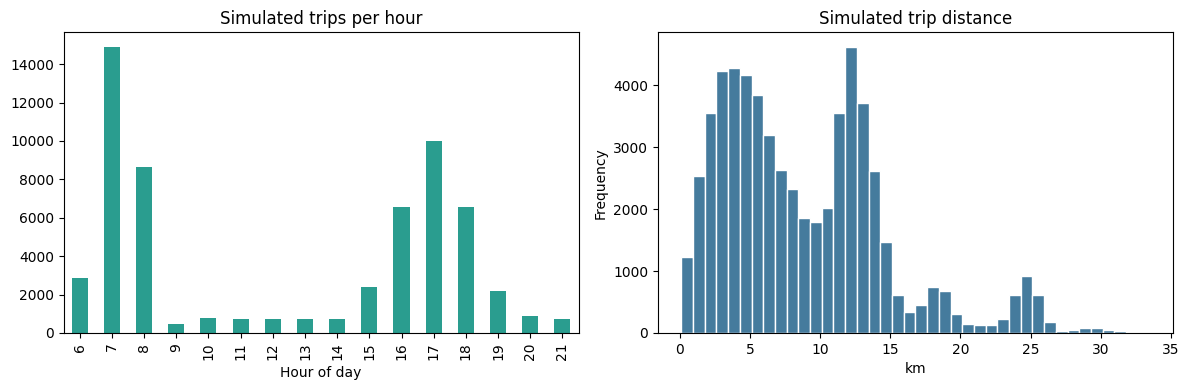

In [48]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
df['hour'].value_counts().sort_index().plot(kind='bar', color='#2a9d8f', ax=ax[0])
ax[0].set_title('Simulated trips per hour'); ax[0].set_xlabel('Hour of day')
df['km'].plot(kind='hist', bins=40, color='#457b9d', edgecolor='white', ax=ax[1])
ax[1].set_title('Simulated trip distance'); ax[1].set_xlabel('km')
plt.tight_layout(); plt.show()

## 6.4 Convert to kilometres

The **centre point and the km-per-degree values are saved in the model file**, because the app must convert new rides in exactly the same way.

In [49]:
lat0, lon0 = df['slat'].mean(), df['slon'].mean()
km_per_lat = 110.57
km_per_lon = 111.32 * np.cos(np.radians(lat0))

df['s_y'] = (df['slat'] - lat0) * km_per_lat
df['s_x'] = (df['slon'] - lon0) * km_per_lon
df['t_y'] = (df['tlat'] - lat0) * km_per_lat
df['t_x'] = (df['tlon'] - lon0) * km_per_lon
X = df[['s_y', 's_x', 't_y', 't_x']]
print('Centre:', round(lat0, 5), round(lon0, 5), '| km per degree lon:', round(km_per_lon, 3))

Centre: -1.30896 36.81575 | km per degree lon: 111.291


## 6.5 Choose k

Same rule as Section 4: try k = 2 to 12, then pick the k between 3 and 10 with the lowest Davies-Bouldin score and check it against the elbow.
We allow up to 10 here (Porto allowed up to 8) because student routes fan out from one campus to many neighbourhoods, so more corridors are expected.

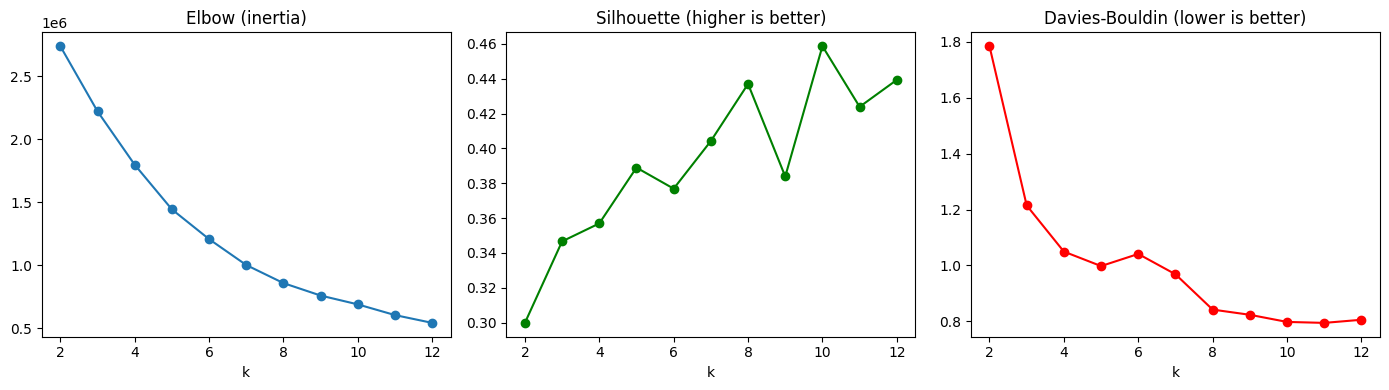

 k   inertia  silhouette  davies_bouldin
 2 2740129.0       0.300           1.784
 3 2223059.0       0.347           1.215
 4 1799144.0       0.357           1.049
 5 1444991.0       0.389           0.998
 6 1208866.0       0.377           1.041
 7 1003355.0       0.404           0.968
 8  859912.0       0.437           0.842
 9  761071.0       0.384           0.823
10  690990.0       0.459           0.798
11  606050.0       0.424           0.794
12  544266.0       0.439           0.806

Chosen k = 10


In [50]:
X_s = X.sample(min(30000, len(X)), random_state=42)
k_values = range(2, 13)
inertia, sil, dbi = [], [], []
for k in k_values:
    km = KMeans(n_clusters=k, n_init=5, random_state=42).fit(X_s)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(X_s, km.labels_, sample_size=10000, random_state=42))
    dbi.append(davies_bouldin_score(X_s, km.labels_))

fig, ax = plt.subplots(1, 3, figsize=(14, 4))
ax[0].plot(k_values, inertia, marker='o'); ax[0].set_title('Elbow (inertia)')
ax[1].plot(k_values, sil, marker='o', color='green'); ax[1].set_title('Silhouette (higher is better)')
ax[2].plot(k_values, dbi, marker='o', color='red'); ax[2].set_title('Davies-Bouldin (lower is better)')
for a in ax: a.set_xlabel('k')
plt.tight_layout(); plt.show()

scores = pd.DataFrame({'k': list(k_values), 'inertia': np.round(inertia),
                       'silhouette': np.round(sil, 3), 'davies_bouldin': np.round(dbi, 3)})
print(scores.to_string(index=False))

candidates = [k for k in k_values if 3 <= k <= 10]
K = min(candidates, key=lambda k: dbi[k - 2])
print('\nChosen k =', K)

## 6.6 Train on 80%, check on the unseen 20%

In [51]:
X_train, X_test = train_test_split(X, test_size=0.2, random_state=42)
model = KMeans(n_clusters=K, n_init=10, random_state=42).fit(X_train)
test_labels = model.predict(X_test)

print('Silhouette     train:', round(silhouette_score(X_train, model.labels_, sample_size=10000, random_state=42), 3),
      '| test:', round(silhouette_score(X_test, test_labels, sample_size=10000, random_state=42), 3))
print('Davies-Bouldin train:', round(davies_bouldin_score(X_train, model.labels_), 3),
      '| test:', round(davies_bouldin_score(X_test, test_labels), 3))

# stability: different random starts should give similar inertia
inertias = [KMeans(n_clusters=K, n_init=1, random_state=s).fit(X_s).inertia_ for s in [1, 7, 21, 42, 99]]
print('Inertia with 5 seeds:', [round(i) for i in inertias])

Silhouette     train: 0.411 | test: 0.409
Davies-Bouldin train: 0.78 | test: 0.783
Inertia with 5 seeds: [676833, 673578, 778872, 712195, 761089]


## 6.7 What each cluster means

Each centre is a typical route (a travel corridor). We name each cluster after the **most common start areas and end areas** of the trips inside it. A corridor can cover neighbouring areas (for example, everything south-west of campus), so up to two names are shown on each side.

In [52]:
df['cluster'] = model.predict(X)
centers = pd.DataFrame(model.cluster_centers_, columns=['s_y', 's_x', 't_y', 't_x'])

def top_places(names, n=2):
    # the 1-2 most common place names (second one only if it is at least 25% of the cluster)
    vc = names.value_counts(normalize=True)
    keep = [vc.index[0]] + [p for p, share in vc.iloc[1:n].items() if share >= 0.25]
    return ' / '.join(keep)

labels = []
for i in range(K):
    g = df[df['cluster'] == i]
    start, end = top_places(g['start_place']), top_places(g['end_place'])
    if start == end:
        # short trips in both directions around the same place (e.g. campus <-> nearby estates)
        nearby = pd.concat([g['start_place'], g['end_place']])
        nearby = nearby[nearby != start].value_counts().index[:3]
        labels.append(f"Short trips around {start} ({', '.join(nearby)})")
    else:
        labels.append(f"{start} → {end}")

summary = pd.DataFrame({
    'cluster': range(K),
    'typical route': labels,
    'share %': (df['cluster'].value_counts(normalize=True).sort_index() * 100).round(1).values,
    'avg km': df.groupby('cluster')['km'].mean().round(2).values,
    'busiest hour': df.groupby('cluster')['hour'].agg(lambda h: h.value_counts().idxmax()).values,
})
print(summary.to_string(index=False))

 cluster                                                                        typical route  share %  avg km  busiest hour
       0                                     Ongata Rongai / Lang'ata → Strathmore University     11.8   11.87             7
       1 Short trips around Strathmore University (South B, South C, Madaraka / Nairobi West)     29.3    3.22            17
       2                                Strathmore University → Buruburu / Donholm / Embakasi      8.4   11.01            17
       3                                          Kasarani / Roysambu → Strathmore University      4.3   12.72             7
       4                                     Strathmore University → Ongata Rongai / Lang'ata     10.8   11.93            17
       5                                                    Kitengela → Strathmore University      2.3   24.86             7
       6                                                     Kilimani → Strathmore University     15.9    6.02             7


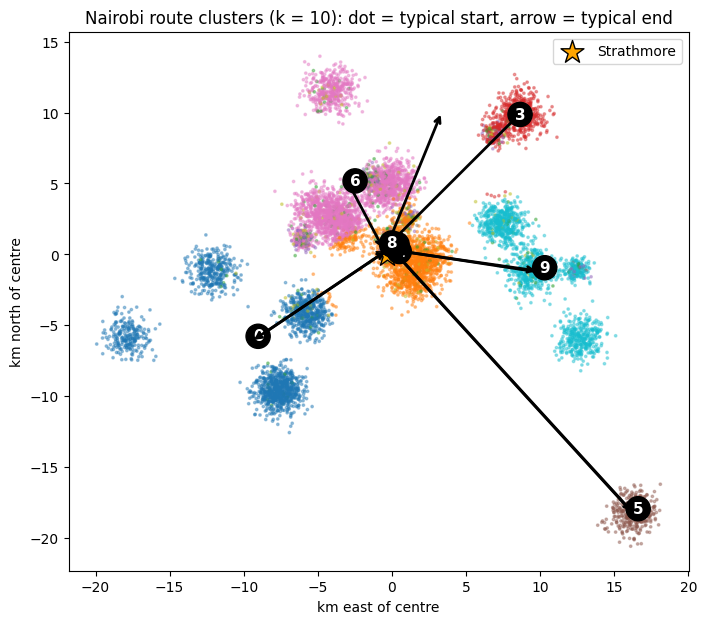

In [53]:
sample = df.sample(min(15000, len(df)), random_state=1)
plt.figure(figsize=(8, 7))
plt.scatter(sample['s_x'], sample['s_y'], c=sample['cluster'], cmap='tab10', s=3, alpha=0.4)
for i, c in centers.iterrows():
    plt.annotate('', xy=(c['t_x'], c['t_y']), xytext=(c['s_x'], c['s_y']),
                 arrowprops=dict(arrowstyle='->', color='black', lw=2))
    plt.text(c['s_x'], c['s_y'], str(i), fontsize=11, fontweight='bold', color='white',
             bbox=dict(boxstyle='circle', fc='black'))
cy, cx = (CAMPUS[1] - lat0) * km_per_lat, (CAMPUS[2] - lon0) * km_per_lon
plt.scatter([cx], [cy], marker='*', s=300, c='orange', edgecolors='black', label='Strathmore')
plt.legend(); plt.xlabel('km east of centre'); plt.ylabel('km north of centre')
plt.title(f'Nairobi route clusters (k = {K}): dot = typical start, arrow = typical end')
plt.show()

## 6.8 Does the cluster help matching?

In the app, a passenger is matched with rides **in the same cluster** that leave **within 60 minutes**, then ranked by how close the pick-up and drop-off points are.
Here we check that trips in the same cluster really have closer pick-ups and drop-offs than random pairs.

In [54]:
pairs = 20000
a = df.sample(pairs, replace=True, random_state=1).reset_index(drop=True)
b = df.sample(pairs, replace=True, random_state=2).reset_index(drop=True)
gap = (haversine(a['slon'], a['slat'], b['slon'], b['slat'])
       + haversine(a['tlon'], a['tlat'], b['tlon'], b['tlat']))
same = a['cluster'] == b['cluster']
print('Pick-up + drop-off gap, same cluster     :', round(gap[same].median(), 2), 'km (median)')
print('Pick-up + drop-off gap, different cluster:', round(gap[~same].median(), 2), 'km (median)')

# share of test-period trips that have at least one match (same cluster, same day, within 60 min)
WINDOW = 60
d = df[['timestamp', 'cluster']].copy()
d['date'] = d['timestamp'].dt.date
d['minute'] = d['timestamp'].dt.hour * 60 + d['timestamp'].dt.minute
d = d.sort_values(['cluster', 'date', 'minute']).reset_index(drop=True)
has_match = np.zeros(len(d), bool)
for _, g in d.groupby(['cluster', 'date']):
    m = g['minute'].values
    lo = np.searchsorted(m, m - WINDOW, 'left'); hi = np.searchsorted(m, m + WINDOW, 'right')
    has_match[g.index] = (hi - lo) > 1
print(f'Trips with at least one possible match (same cluster, within {WINDOW} min):',
      round(has_match.mean() * 100, 1), '%')

Pick-up + drop-off gap, same cluster     : 5.83 km (median)
Pick-up + drop-off gap, different cluster: 16.54 km (median)
Trips with at least one possible match (same cluster, within 60 min): 97.7 %


## 6.9 Export the model for the Android app

The file holds everything the app needs to repeat the prediction: the centre point, the km conversion and the K cluster centres.
Prediction in the app = convert the ride to km, then pick the **nearest cluster centre** (exactly what `model.predict` does).


In [55]:
export = {
    'model': 'kmeans',
    'version': 1,
    'trained_on': 'simulated Strathmore student trips (Nairobi), replace with real UniPool rides when available',
    'k': int(K),
    'features': ['s_y', 's_x', 't_y', 't_x'],
    'lat0': float(lat0),
    'lon0': float(lon0),
    'km_per_lat': float(km_per_lat),
    'km_per_lon': float(km_per_lon),
    'centroids': [[round(float(v), 6) for v in row] for row in model.cluster_centers_],
    'cluster_labels': labels,
    'match_window_minutes': WINDOW,
}
with open('unipool_kmeans.json', 'w') as f:
    json.dump(export, f, indent=2, ensure_ascii=False)

# check: the formula used in the app gives the same clusters as scikit-learn
C = np.array(export['centroids'])
app_pred = np.argmin(((X.values[:, None, :] - C[None, :, :]) ** 2).sum(axis=2), axis=1)
print('App formula agrees with model.predict on', round((app_pred == df['cluster'].values).mean() * 100, 2), '% of trips')
print(json.dumps(export, indent=2, ensure_ascii=False)[:600], '...')

try:
    from google.colab import files
    files.download('unipool_kmeans.json')     # downloads the file in Colab
except ImportError:
    print('Not running in Colab: file saved next to the notebook.')

App formula agrees with model.predict on 100.0 % of trips
{
  "model": "kmeans",
  "version": 1,
  "trained_on": "simulated Strathmore student trips (Nairobi), replace with real UniPool rides when available",
  "k": 10,
  "features": [
    "s_y",
    "s_x",
    "t_y",
    "t_x"
  ],
  "lat0": -1.3089627248599625,
  "lon0": 36.815745269788614,
  "km_per_lat": 110.57,
  "km_per_lon": 111.29095083812106,
  "centroids": [
    [
      -6.088693,
      -9.388239,
      0.315489,
      -0.288993
    ],
    [
      -0.11384,
      0.13757,
      1.144218,
      -0.756244
    ],
    [
      0.360165,
      -0.377904,
      -1.173386,
      9.893738
    ],
    ...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Conclusion of the final model
We retrained the same spatial K-Means pipeline on Nairobi routes centred on Strathmore University. Train and test scores are almost identical, so the model does not overfit. With a single random start, inertia changes by up to about 15% between seeds, so the final model uses `n_init=10` and keeps the best of 10 starts. Trips in the same cluster have much closer pick-ups and drop-offs than trips in different clusters, which supports using the cluster as the first matching filter.

**Limitation:** the Nairobi trips are simulated from assumptions. The next step is to re-run this section on real rides exported from Firestore.

## 7. How the app uses the model (explainable matching)

The exported file is copied into the Android app (`app/src/main/assets/unipool_kmeans.json`). The app repeats the model's prediction on the phone:

1. **Driver posts a ride:** the pick-up and destination (chosen from Google place search or a built-in list of Nairobi places) are converted to km with the same `lat0`, `lon0`, `km_per_lat`, `km_per_lon` values, and the ride is given the **nearest cluster centre** – this is exactly what `model.predict()` does. The driver sees the route group, e.g. *"Ongata Rongai / Lang'ata → Strathmore University"*.
2. **Passenger searches (Smart Match):** the passenger's trip is assigned to a cluster the same way. The app keeps rides that are
   - in the **same route cluster**,
   - leaving within **60 minutes** of the passenger's time,
   - with pick-up and drop-off each within **6 km** of the passenger's.
3. **Ranking:** score = pick-up distance + drop-off distance + (minutes apart ÷ 30). Lower is better.
4. **Explanation shown to the user:** every recommended ride shows the route group and *"Pick-up X km from yours · drop-off Y km from yours · Z min from your time"*, so the student can see why it was recommended.

**Invalid inputs handled by the app:** missing pick-up or destination, the same place for both, a departure time in the past, and invalid seats or contribution are rejected with a message. Rides in a different cluster or outside the time window are not recommended.

In [56]:
# Check: the same prediction the app performs, on a few example trips
C = np.array(export['centroids'])

def app_predict(from_lat, from_lng, to_lat, to_lng):
    f = np.array([(from_lat - export['lat0']) * export['km_per_lat'],
                  (from_lng - export['lon0']) * export['km_per_lon'],
                  (to_lat   - export['lat0']) * export['km_per_lat'],
                  (to_lng   - export['lon0']) * export['km_per_lon']])
    return int(np.argmin(((C - f) ** 2).sum(axis=1)))     # nearest cluster centre

examples = {
    'Ongata Rongai -> Strathmore': (-1.3960, 36.7470, -1.3096, 36.8126),
    'Strathmore -> Ongata Rongai': (-1.3096, 36.8126, -1.3960, 36.7470),
    'Westlands -> Strathmore':     (-1.2676, 36.8108, -1.3096, 36.8126),
    'Strathmore -> Kasarani':      (-1.3096, 36.8126, -1.2210, 36.8970),
}
for name, trip in examples.items():
    c = app_predict(*trip)
    print(f'{name:30s} -> cluster {c}: {export["cluster_labels"][c]}')

Ongata Rongai -> Strathmore    -> cluster 0: Ongata Rongai / Lang'ata → Strathmore University
Strathmore -> Ongata Rongai    -> cluster 4: Strathmore University → Ongata Rongai / Lang'ata
Westlands -> Strathmore        -> cluster 6: Kilimani → Strathmore University
Strathmore -> Kasarani         -> cluster 8: Strathmore University → Kasarani / Roysambu / Ruaka
